In [ ]:
# ==========================================
# Phase 4 - Cell 1: Authentication & Setup
# ==========================================
import pandas as pd
from google.colab import auth
from google.cloud import bigquery
import pandas_gbq

print("🔒 در حال احراز هویت... لطفاً دسترسی‌های لازم را به اکانت گوگل بدهید.")
auth.authenticate_user()

PROJECT_ID = 'siavak-temp-aliz'  # شناسه پروژه شما
DATASET_ID = 'divar_ml_data_prepration' # نام دیتاست شما
client = bigquery.Client(project=PROJECT_ID)

print(f"✅ احراز هویت با موفقیت انجام شد. متصل به پروژه: {PROJECT_ID}")

🔒 در حال احراز هویت... لطفاً دسترسی‌های لازم را به اکانت گوگل بدهید.
✅ احراز هویت با موفقیت انجام شد. متصل به پروژه: siavak-temp-aliz


In [ ]:
# ==========================================
# Phase 4 - Cell 2: Load Macro Data, Honest Smart Lags & Upload
# ==========================================
import pandas as pd
import numpy as np
import pandas_gbq

print("⏳ ۱. در حال بارگذاری و پاکسازی دیتابیس کلان...")

file_name = 'Iran_Monthly_Macro_1395_1405.xlsx'
try:
    df_macro = pd.read_excel(file_name, sheet_name='Monthly_Data')
except:
    df_macro = pd.read_csv('Iran_Monthly_Macro_1395_1405.csv')

# متغیرهایی که از فایل می‌خوانیم
cols_to_keep = ['Year_Jalali', 'Month_Jalali', 'Inflation_General_YoY',
                'Inflation_Housing_YoY', 'Construction_Cost_YoY',
                'USD_Free_Market', 'Liquidity_M2_Growth', 'TEDPIX_Index']
df_macro = df_macro[cols_to_keep].copy()

# 🛠️ پاکسازی متون و خط تیره (-)
for col in cols_to_keep:
    if df_macro[col].dtype == 'object':
        df_macro[col] = df_macro[col].astype(str).str.replace(',', '').str.strip()
        df_macro[col] = df_macro[col].replace(['-', ''], np.nan)
        df_macro[col] = pd.to_numeric(df_macro[col], errors='coerce')

df_macro = df_macro.sort_values(by=['Year_Jalali', 'Month_Jalali']).reset_index(drop=True)

# ------------------------------------------
print("⏳ ۲. در حال مهندسی ویژگی‌های تاخیری (Honest Smart Lags)...")

# گروه اول: متغیرهای لحظه‌ای بازار آزاد (مجاز به داشتن لگ ۱، ۳، ۶ و حتی زمان حال)
# دقت کن: زمان حال را نگه می‌داریم چون در اجرای زنده دلار همون روز در دسترس است
market_features = ['USD_Free_Market', 'TEDPIX_Index']
for col in market_features:
    for lag in [1, 3, 6]:
        df_macro[f"{col}_Lag_{lag}"] = df_macro[col].shift(lag)

# گروه دوم: متغیرهای کُند و دولتی (برای جلوگیری از نشت انتشار، فقط لگ ۳ و ۶ مجاز است)
gov_features = ['Inflation_General_YoY', 'Construction_Cost_YoY', 'Liquidity_M2_Growth']
for col in gov_features:
    for lag in [3, 6]:
        df_macro[f"{col}_Lag_{lag}"] = df_macro[col].shift(lag)

# 🚨 حذف تقلب (Data Leakage): حذف دیتای فعلیِ آمارهای دولتی که با تاخیر منتشر می‌شوند!
df_macro = df_macro.drop(columns=gov_features)

# پر کردن مقادیر خالی ابتدای سال ۹۵ با اولین دیتای در دسترس
df_macro = df_macro.bfill()

# ------------------------------------------
print("⏳ ۳. در حال تعریف Schema و آپلود به BigQuery...")

base_descriptions = {
    'Year_Jalali': 'سال شمسی انتشار داده',
    'Month_Jalali': 'ماه شمسی انتشار داده',
    'Inflation_Housing_YoY': 'تورم مسکن (فقط برای جوین شدن استفاده می‌شود، در تمرین حذف می‌شود)',
    'Inflation_General_YoY': 'تورم نقطه به نقطه کل',
    'Construction_Cost_YoY': 'تورم نهاده‌های ساختمانی',
    'USD_Free_Market': 'میانگین قیمت دلار آزاد (تومان)',
    'Liquidity_M2_Growth': 'رشد نقدینگی (M2)',
    'TEDPIX_Index': 'شاخص کل بورس'
}

table_schema = []
for col in df_macro.columns:
    if '_Lag_' in col:
        base_col = col.split('_Lag_')[0]
        lag_num = col.split('_Lag_')[1]
        desc = f"{base_descriptions.get(base_col, '')} - (تاخیر {lag_num} ماهه)"
    else:
        desc = base_descriptions.get(col, '')

    bq_type = 'INTEGER' if col in ['Year_Jalali', 'Month_Jalali'] else 'FLOAT'
    table_schema.append({'name': col, 'type': bq_type, 'description': desc})

table_name = "macro_monthly_database"
destination_table = f"{PROJECT_ID}.{DATASET_ID}.{table_name}"

pandas_gbq.to_gbq(
    df_macro,
    destination_table=destination_table,
    project_id=PROJECT_ID,
    if_exists='replace',
    table_schema=table_schema
)

print(f"🎉 عملیات موفقیت‌آمیز بود! دیتابیس کلانِ پاکسازی شده از تقلب در آدرس زیر ذخیره شد:")
print(f"📌 {destination_table}")
print(f"✅ تعداد کل ستون‌های نهایی: {df_macro.shape[1]}")

⏳ ۱. در حال بارگذاری و پاکسازی دیتابیس کلان...
⏳ ۲. در حال مهندسی ویژگی‌های تاخیری (Honest Smart Lags)...
⏳ ۳. در حال تعریف Schema و آپلود به BigQuery...


100%|██████████| 1/1 [00:00<00:00, 7810.62it/s]

🎉 عملیات موفقیت‌آمیز بود! دیتابیس کلانِ پاکسازی شده از تقلب در آدرس زیر ذخیره شد:
📌 siavak-temp-aliz.divar_ml_data_prepration.macro_monthly_database
✅ تعداد کل ستون‌های نهایی: 17


In [ ]:
# ==========================================
# Phase 4 - Cell 3: Merge Macro Features with Base Prices (Clean Dates)
# ==========================================
import pandas as pd
from google.cloud import bigquery
import pandas_gbq

print("⏳ ۱. در حال دانلود جدول اقتصاد کلان و جدول قیمت‌های پایه از BigQuery...")

# دانلود جداول
query_macro = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.macro_monthly_database`"
df_macro = pandas_gbq.read_gbq(query_macro, project_id=PROJECT_ID)

query_prices = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.ref_macro_prices`"
df_prices = pandas_gbq.read_gbq(query_prices, project_id=PROJECT_ID)

print("⏳ ۲. در حال استانداردسازی فرمت تاریخ و پیوند (Join) جداول...")

# ساخت ستون موقت year_month در جدول کلان فقط برای پیوند زدن
df_macro['year_month'] = df_macro['Year_Jalali'].astype(str) + '-' + df_macro['Month_Jalali'].astype(str).str.zfill(2)

# استانداردسازی ستون year_month در جدول قیمت‌ها
df_prices['year_month'] = df_prices['year_month'].astype(str).str.replace('_', '-').str.replace('/', '-')
df_prices['year_month'] = df_prices['year_month'].apply(
    lambda x: f"{x.split('-')[0]}-{x.split('-')[1].zfill(2)}" if len(x.split('-')) == 2 else x
)

# پیوند زدن دو جدول
df_macro_train = pd.merge(df_prices, df_macro, on='year_month', how='inner')

# 🧹 پاکسازی طلایی: حذف ستون متنی year_month و نگه داشتن سال و ماه تفکیک شده برای XGBoost
df_macro_train.drop(columns=['year_month'], inplace=True)

# مرتب‌سازی منطقی: اول بر اساس منطقه، بعد بر اساس زمان
df_macro_train = df_macro_train.sort_values(by=['region_id', 'Year_Jalali', 'Month_Jalali']).reset_index(drop=True)

print(f"✅ پیوند جداول و پاکسازی تاریخ‌ها با موفقیت انجام شد!")
print(f"📊 ابعاد دیتاسِت نهایی آموزش مدل کلان: {df_macro_train.shape[0]} ردیف و {df_macro_train.shape[1]} ستون")

print("⏳ ۳. در حال آپلود دیتاسِت نهایی آموزش به BigQuery...")
table_name = "macro_training_dataset"
destination_table = f"{PROJECT_ID}.{DATASET_ID}.{table_name}"

pandas_gbq.to_gbq(df_macro_train, destination_table=destination_table, project_id=PROJECT_ID, if_exists='replace')

print(f"🎉 دیتاسِت آموزشِ مدل کلان آماده شد و در مسیر زیر ذخیره شد:")
print(f"📌 {destination_table}")
print("-" * 50)
print("🔍 پیش‌نمایش ۳ ردیف اول (تمیز شده و آماده برای مدل):")
display(df_macro_train.head(3))

⏳ ۱. در حال دانلود جدول اقتصاد کلان و جدول قیمت‌های پایه از BigQuery...
Downloading: 100%|██████████|
Downloading: 100%|██████████|
⏳ ۲. در حال استانداردسازی فرمت تاریخ و پیوند (Join) جداول...
✅ پیوند جداول و پاکسازی تاریخ‌ها با موفقیت انجام شد!
📊 ابعاد دیتاسِت نهایی آموزش مدل کلان: 1386 ردیف و 19 ستون
⏳ ۳. در حال آپلود دیتاسِت نهایی آموزش به BigQuery...


100%|██████████| 1/1 [00:00<00:00, 8830.11it/s]

🎉 دیتاسِت آموزشِ مدل کلان آماده شد و در مسیر زیر ذخیره شد:
📌 siavak-temp-aliz.divar_ml_data_prepration.macro_training_dataset
--------------------------------------------------
🔍 پیش‌نمایش ۳ ردیف اول (تمیز شده و آماده برای مدل):


,region_id,macro_price_per_sqm,Year_Jalali,Month_Jalali,Inflation_Housing_YoY,USD_Free_Market,TEDPIX_Index,USD_Free_Market_Lag_1,USD_Free_Market_Lag_3,USD_Free_Market_Lag_6,TEDPIX_Index_Lag_1,TEDPIX_Index_Lag_3,TEDPIX_Index_Lag_6,Inflation_General_YoY_Lag_3,Inflation_General_YoY_Lag_6,Construction_Cost_YoY_Lag_3,Construction_Cost_YoY_Lag_6,Liquidity_M2_Growth_Lag_3,Liquidity_M2_Growth_Lag_6
0,1,78.49,1400,1,31.287689,25138.39,1207046.9,25123.67,25115.00,29972.67,1307657.4,1183978.2,1412354.66,45.513052,41.308973,97.21468,101.55512,40.6,38.4
1,1,78.98,1400,2,29.156033,22917.74,1128164.1,25138.39,24585.67,27610.00,1207046.9,1238397.8,1366535.20,47.209058,45.727331,97.21468,101.55512,40.6,38.4
2,1,80.15,1400,3,28.569912,23858.06,1186905.5,22917.74,25123.67,25815.67,1128164.1,1307657.4,1436392.90,47.842984,44.170772,97.21468,101.55512,40.6,38.4


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 16.0 MB/s eta 0:00:00
⏳ ۱. در حال دانلود دیتاسِت آموزش از BigQuery...
Downloading: 100%|██████████|
⏳ ۲. در حال آماده‌سازی ویژگی‌ها (Features) و متغیر هدف (Target)...
⏳ ۳. برش زمانی داده‌ها (Time-Based Split)...
✅ داده‌های آموزش: 1178 رکورد | داده‌های تست (آینده): 208 رکورد
⏳ ۴. شروع عملیات بهینه‌سازی پارامترها با Optuna (جستجوی بیزی)...
🏆 بهترین تنظیمات کشف شده: {'n_estimators': 1349, 'max_depth': 8, 'learning_rate': 0.007309551465623384, 'subsample': 0.7188861356654745, 'colsample_bytree': 0.8217451167581209}
⏳ ۵. آموزش مدل نهایی و ارزیابی...
--------------------------------------------------
🎯 خطای مدل (MAPE): 3.39%
💵 میانگین خطای ریالی (RMSE): 8 تومان بر متر مربع
--------------------------------------------------


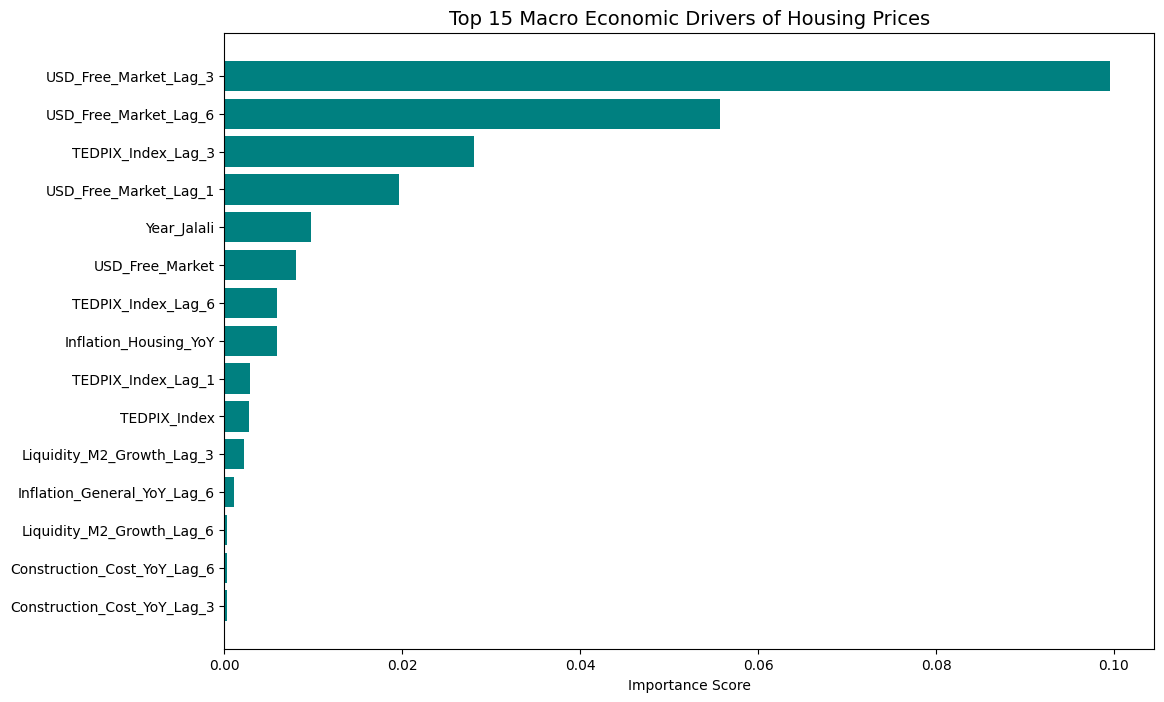

In [ ]:
# ==========================================
# Phase 4 - Cell 4: Train Advanced Macro XGBoost Model (Optuna + TimeSplit)
# ==========================================
# نصب کتابخانه اپتونا در صورت عدم وجود
!pip install optuna -q

import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import pandas_gbq
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("⏳ ۱. در حال دانلود دیتاسِت آموزش از BigQuery...")
query = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.macro_training_dataset`"
df = pandas_gbq.read_gbq(query, project_id=PROJECT_ID)

# 🛠️ مرتب‌سازی اکید بر اساس زمان (جلوگیری از Data Leakage یا تقلب مدل)
df = df.sort_values(by=['Year_Jalali', 'Month_Jalali']).reset_index(drop=True)

print("⏳ ۲. در حال آماده‌سازی ویژگی‌ها (Features) و متغیر هدف (Target)...")
# تبدیل منطقه به One-Hot Encoding تا مدل روابط مکانی را بهتر درک کند
df = pd.get_dummies(df, columns=['region_id'], drop_first=False)

# متغیر هدف (قیمت پایه منطقه)
target = 'macro_price_per_sqm'
X = df.drop(columns=[target])
y = df[target]

print("⏳ ۳. برش زمانی داده‌ها (Time-Based Split)...")
# استفاده از ۸۵ درصد داده‌های قدیمی برای آموزش و ۱۵ درصد جدید برای تست
split_index = int(len(df) * 0.85)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"✅ داده‌های آموزش: {len(X_train)} رکورد | داده‌های تست (آینده): {len(X_test)} رکورد")

# ------------------------------------------
print("⏳ ۴. شروع عملیات بهینه‌سازی پارامترها با Optuna (جستجوی بیزی)...")

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1500),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 50
    }

    model = xgb.XGBRegressor(**params)
    model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

    preds = model.predict(X_test)
    mape = mean_absolute_percentage_error(y_test, preds)
    return mape

# بی‌صدا کردن لاگ‌های اضافی Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=35) # اجرای ۳۵ تست هوشمند

print("🏆 بهترین تنظیمات کشف شده:", study.best_params)

# ------------------------------------------
print("⏳ ۵. آموزش مدل نهایی و ارزیابی...")
# حذف پارامتر early_stopping_rounds برای آموزش نهایی روی کل دیتای ترین
best_params = study.best_params
best_params['random_state'] = 42

final_model = xgb.XGBRegressor(**best_params)
final_model.fit(X_train, y_train)

# ارزیابی روی داده‌های تست (که مدل هرگز ندیده است)
y_pred = final_model.predict(X_test)
final_mape = mean_absolute_percentage_error(y_test, y_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("-" * 50)
print(f"🎯 خطای مدل (MAPE): {final_mape * 100:.2f}%")
print(f"💵 میانگین خطای ریالی (RMSE): {final_rmse:,.0f} تومان بر متر مربع")
print("-" * 50)

# رسم نمودار اهمیت ویژگی‌ها (Feature Importance)
plt.figure(figsize=(12, 8))
# نمایش ۱۵ متغیر برتر (بدون ستون‌های منطقه برای وضوح بیشتر کلان)
importances = final_model.feature_importances_
feature_names = X_train.columns
macro_features_only = [(name, imp) for name, imp in zip(feature_names, importances) if 'region_id' not in name]
macro_features_only.sort(key=lambda x: x[1], reverse=True)

top_names = [x[0] for x in macro_features_only[:15]]
top_imps = [x[1] for x in macro_features_only[:15]]

plt.barh(top_names[::-1], top_imps[::-1], color='teal')
plt.title('Top 15 Macro Economic Drivers of Housing Prices', fontsize=14)
plt.xlabel('Importance Score')
plt.show()

⏳ در حال محاسبه مقادیر SHAP روی کل مدل (کالبدشکافی هوش مصنوعی)...
✅ تحلیل SHAP با موفقیت انجام شد!
--------------------------------------------------
💡 راهنمای خواندن نمودار:
- محور افقی (SHAP Value): تاثیر روی قیمت. سمت راست یعنی افزایش قیمت، سمت چپ یعنی کاهش قیمت.
- رنگ نقطه‌ها: قرمز یعنی مقدار آن متغیر بالا (زیاد) بوده، آبی یعنی پایین (کم) بوده.
- مثال: اگر نقطه‌های قرمز رنگ مربوط به دلار سمت راست باشند، یعنی بالا رفتن دلار باعث افزایش قیمت پایه مناطق می‌شود.
--------------------------------------------------


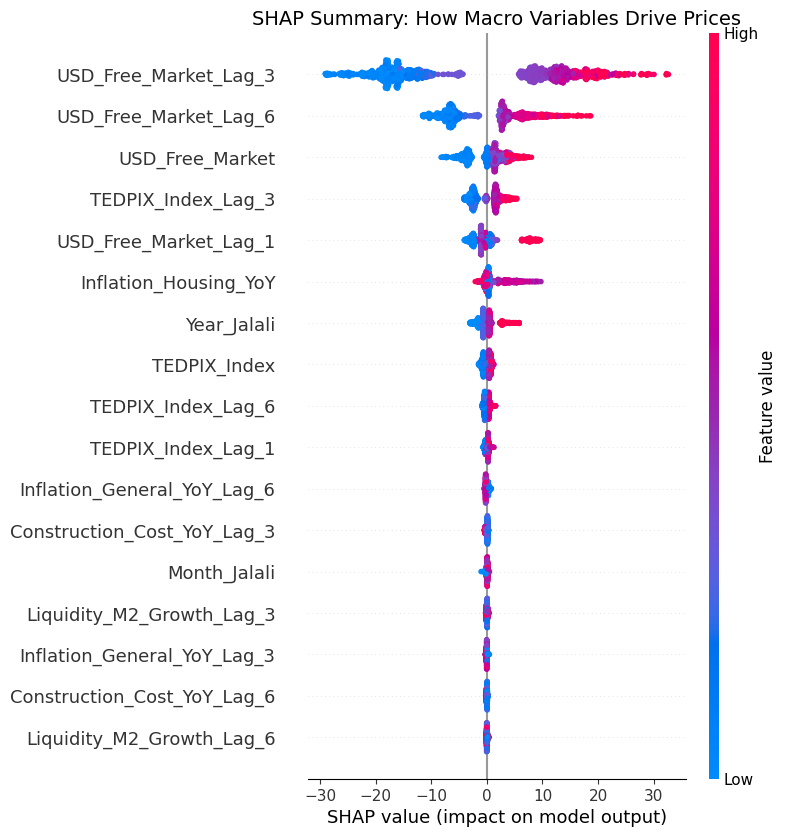

In [ ]:
# ==========================================
# Phase 4 - Cell 5: Explainability with SHAP Values (Corrected)
# ==========================================
import shap
import matplotlib.pyplot as plt

print("⏳ در حال محاسبه مقادیر SHAP روی کل مدل (کالبدشکافی هوش مصنوعی)...")

# ۱. محاسبه SHAP روی دقیقاً همان ساختاری که مدل آموزش دیده است (کل X_train)
explainer = shap.TreeExplainer(final_model)
shap_values_full = explainer.shap_values(X_train) # 👈 تغییر اصلی اینجاست

# ۲. استخراج ایندکس (موقعیت) ستون‌هایی که مربوط به اقتصاد کلان هستند (حذف مناطق)
macro_cols = [col for col in X_train.columns if 'region_id' not in col]
macro_indices = [X_train.columns.get_loc(col) for col in macro_cols]

# ۳. فیلتر کردن مقادیر SHAP و دیتافریم صرفاً برای زمانِ رسم نمودار
shap_values_macro = shap_values_full[:, macro_indices]
X_train_macro = X_train.iloc[:, macro_indices]

print("✅ تحلیل SHAP با موفقیت انجام شد!")
print("-" * 50)
print("💡 راهنمای خواندن نمودار:")
print("- محور افقی (SHAP Value): تاثیر روی قیمت. سمت راست یعنی افزایش قیمت، سمت چپ یعنی کاهش قیمت.")
print("- رنگ نقطه‌ها: قرمز یعنی مقدار آن متغیر بالا (زیاد) بوده، آبی یعنی پایین (کم) بوده.")
print("- مثال: اگر نقطه‌های قرمز رنگ مربوط به دلار سمت راست باشند، یعنی بالا رفتن دلار باعث افزایش قیمت پایه مناطق می‌شود.")
print("-" * 50)

# ۴. رسم نمودار زنبوری (Beeswarm) فقط برای متغیرهای کلان
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_macro, X_train_macro, show=False)
plt.title("SHAP Summary: How Macro Variables Drive Prices", fontsize=14)
plt.show()

⏳ ۱. در حال پاکسازی متغیرهای زاید و متقلب (Data Leakage)...
✅ متغیرهای اضافی حذف شدند. تعداد ویژگی‌های خالص: 29
⏳ ۲. شروع بهینه‌سازی مدل خالص با Optuna...
⏳ ۳. آموزش مدل نهاییِ ایزوله...
--------------------------------------------------
🎯 خطای مدل خالص (MAPE): 2.56%
💵 میانگین خطای ریالی (RMSE): 6
--------------------------------------------------


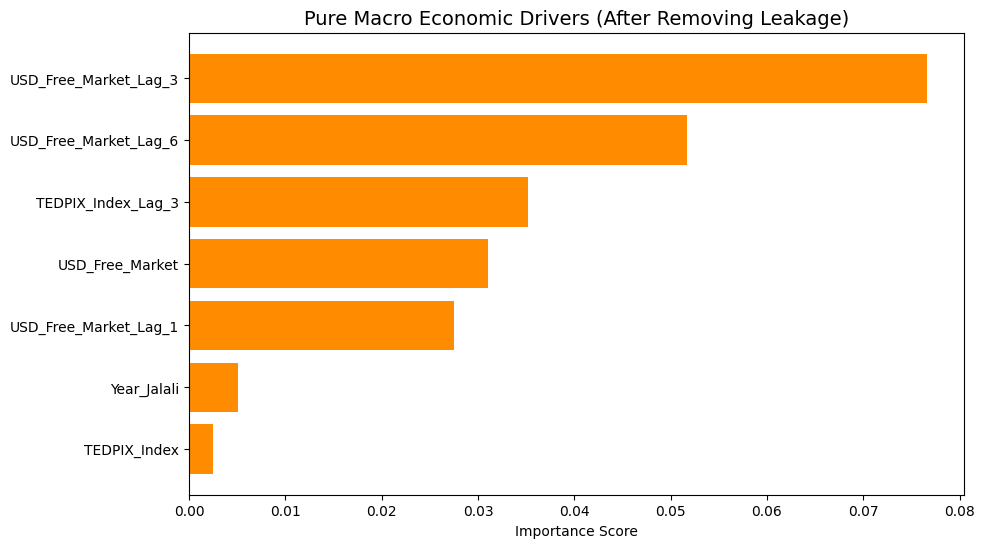

In [ ]:
# ==========================================
# Phase 4 - Cell 6: Clean Retraining (No Leakage, No Noise)
# ==========================================
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("⏳ ۱. در حال پاکسازی متغیرهای زاید و متقلب (Data Leakage)...")

# لیست اعدامی‌ها (متغیرهایی که باید حذف شوند)
# لیست اعدامی‌ها (آپدیت شده دقیقاً بر اساس نمودار SHAP)
cols_to_drop = [
    'Inflation_Housing_YoY', # متقلب اصلی
    'Construction_Cost_YoY', 'Construction_Cost_YoY_Lag_3', 'Construction_Cost_YoY_Lag_6', # بی‌اثر (خط صفر)
    'Inflation_General_YoY', 'Inflation_General_YoY_Lag_1', 'Inflation_General_YoY_Lag_3', 'Inflation_General_YoY_Lag_6', # بی‌اثر (خط صفر)
    'Month_Jalali', # بی‌اثر (خط صفر)
    'Liquidity_M2_Growth_Lag_3', 'Liquidity_M2_Growth_Lag_6', # بی‌اثر (طبق نمودار SHAP)
    'TEDPIX_Index_Lag_1', 'TEDPIX_Index_Lag_6' # تاثیر نزدیک به صفر (طبق نمودار SHAP)
]

# حذف از X_train و X_test که در حافظه نوت‌بوک داریم
X_train_clean = X_train.drop(columns=[col for col in cols_to_drop if col in X_train.columns])
X_test_clean = X_test.drop(columns=[col for col in cols_to_drop if col in X_test.columns])

print(f"✅ متغیرهای اضافی حذف شدند. تعداد ویژگی‌های خالص: {X_train_clean.shape[1]}")

# ------------------------------------------
print("⏳ ۲. شروع بهینه‌سازی مدل خالص با Optuna...")

def objective_clean(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42
    }

    model = xgb.XGBRegressor(**params)
    model.fit(X_train_clean, y_train, verbose=False)

    preds = model.predict(X_test_clean)
    return mean_absolute_percentage_error(y_test, preds)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study_clean = optuna.create_study(direction='minimize')
study_clean.optimize(objective_clean, n_trials=30)

# ------------------------------------------
print("⏳ ۳. آموزش مدل نهاییِ ایزوله...")
best_params_clean = study_clean.best_params
best_params_clean['random_state'] = 42

final_clean_model = xgb.XGBRegressor(**best_params_clean)
final_clean_model.fit(X_train_clean, y_train)

# ارزیابی نهایی
y_pred_clean = final_clean_model.predict(X_test_clean)
final_mape_clean = mean_absolute_percentage_error(y_test, y_pred_clean)
final_rmse_clean = np.sqrt(mean_squared_error(y_test, y_pred_clean))

print("-" * 50)
print(f"🎯 خطای مدل خالص (MAPE): {final_mape_clean * 100:.2f}%")
print(f"💵 میانگین خطای ریالی (RMSE): {final_rmse_clean:,.0f}")
print("-" * 50)

# رسم نمودار اهمیت ویژگی‌های خالص
plt.figure(figsize=(10, 6))
importances = final_clean_model.feature_importances_
feature_names = X_train_clean.columns
macro_features_only = [(name, imp) for name, imp in zip(feature_names, importances) if 'region_id' not in name]
macro_features_only.sort(key=lambda x: x[1], reverse=True)

top_names = [x[0] for x in macro_features_only]
top_imps = [x[1] for x in macro_features_only]

plt.barh(top_names[::-1], top_imps[::-1], color='darkorange')
plt.title('Pure Macro Economic Drivers (After Removing Leakage)', fontsize=14)
plt.xlabel('Importance Score')
plt.show()

In [ ]:
import json
from google.colab import files

# 1. Export Macro Model
final_clean_model.save_model("macro_clean_model.json")
files.download("macro_clean_model.json")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NameError: name 'tuned_model' is not defined